## Langkah 1 — Import library

Bagian ini memanggil library yang dipakai selama praktikum. NLTK digunakan untuk tokenisasi dan lemmatization, Scikit-learn untuk TF-IDF, K-Means, dan PCA, sedangkan Matplotlib untuk membuat grafik. Resource NLTK juga dicek/diunduh agar proses tokenisasi tidak berhenti karena resource belum tersedia.

In [1]:
# Import library
import pandas as pd
import numpy as np
import re
import string
import nltk
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Pastikan resource NLTK yang diperlukan tersedia
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('wordnet')

[nltk_data] Downloading package punkt to C:\Users\Brahmana
[nltk_data]     P\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Brahmana
[nltk_data]     P\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package wordnet to C:\Users\Brahmana
[nltk_data]     P\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

## Langkah 2 — Load dataset

Modul menggunakan file `Text.csv`. File ini punya kolom `Message`, jadi kolom tersebut diganti namanya menjadi `text` agar bisa dipakai pada langkah berikutnya. Simpan `Text.csv` di folder yang sama dengan notebook ini sebelum menjalankan sel.

In [2]:
# Load dataset
file_path = "Text.csv"
df = pd.read_csv(file_path)

# Hanya mengambil kolom message untuk klasterisasi
df = df.rename(columns={'Message': 'text'})

df.head()

,Category,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


## Langkah 3 — Preprocessing, TF-IDF, K-Means, dan PCA

Di sini teks diubah menjadi huruf kecil, angka dan tanda baca dihapus, lalu teks dipecah menjadi token dan kata-katanya dikembalikan ke bentuk dasar. Setelah itu, TF-IDF mengubah teks menjadi angka, K-Means membagi data menjadi dua cluster, dan PCA merangkum fitur ke dua dimensi supaya hasilnya bisa digambar.

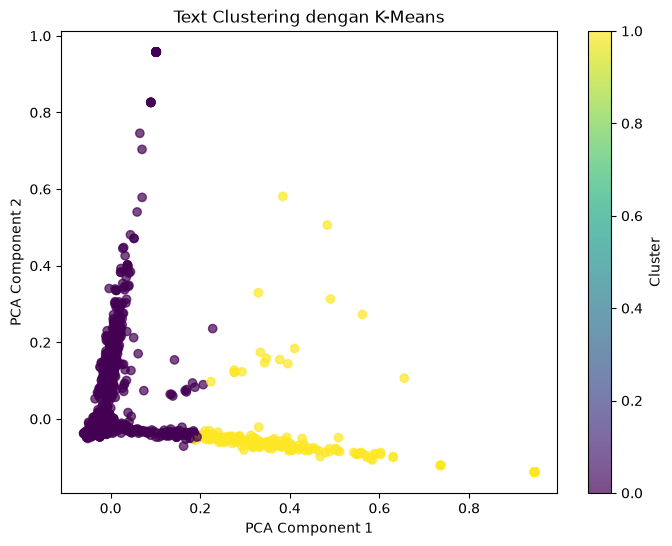

In [3]:
# Inisialisasi lemmatizer
lemmatizer = WordNetLemmatizer()

# Fungsi preprocessing teks
def clean_text(text):
    text = text.lower() # Lowercasing
    text = re.sub(r'\d+', '', text) # Hapus angka
    text = text.translate(str.maketrans('', '', string.punctuation)) # Hapus tanda baca
    words = word_tokenize(text) # Tokenisasi
    words = [lemmatizer.lemmatize(word) for word in words] # Lemmatization
    return ' '.join(words)

# Terapkan preprocessing ke teks
df['clean_text'] = df['text'].apply(clean_text)

# Konversi teks ke vektor TF-IDF
vectorizer = TfidfVectorizer(stop_words='english')      # Menggunakan stopwords dari sklearn
X = vectorizer.fit_transform(df['clean_text'])

# Tentukan jumlah klaster
num_clusters = 2
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
df['cluster'] = kmeans.fit_predict(X)

# Visualisasi dengan PCA
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X.toarray())

plt.figure(figsize=(8, 6))
plt.scatter(X_pca[:, 0], X_pca[:, 1], c=df['cluster'], cmap='viridis', alpha=0.7)
plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Text Clustering dengan K-Means")
plt.colorbar(label='Cluster')
plt.show()

## Catatan hasil

Grafik menampilkan setiap pesan sebagai satu titik. Warna menunjukkan cluster yang diberikan K-Means (cluster 0 atau 1), sedangkan sumbu PCA Component 1 dan 2 adalah proyeksi dua dimensi dari fitur TF-IDF. Nomor cluster hanyalah label kelompok, bukan urutan atau nilai kualitas.